# SNOOPPI: three-seed reproducibility results

## Findings
45 fits completed on the same historical test set. ProtT5 + RF has the highest observed mean macro-AP (0.6189); ESM-C leads full MLPs (0.5997). Both selected component-bootstrap ranges include zero: these exploratory results do not establish superiority.

This notebook reruns aggregate analysis from files in this clone. It displays saved raw-artifact verification receipts; it does not claim to reverify private predictions. The original cloud records are under `records/`.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
HERE=Path.cwd()
if not (HERE/'results/all_metrics.csv').exists(): HERE=HERE/'experiments/reproducibility_20261102'
assert (HERE/'results/all_metrics.csv').exists(), 'Run from the repository root or this notebook directory'
DATA=HERE/'results'
metrics=pd.read_csv(DATA/'all_metrics.csv')
assert len(metrics)==135 and set(metrics.seed)=={44,45,46}
held=metrics[metrics.split=='test'].copy()
assert len(held)==45
held['model']=held.encoder+' / '+held['head']+' / '+held.variant
summary=held.groupby('model').macro_ap.agg(['mean','std','min','max']).sort_values('mean',ascending=False)
saved=pd.read_csv(DATA/'seed_summary.csv',index_col=0)
pd.testing.assert_frame_equal(summary,saved,check_exact=False,rtol=1e-10)
display(summary.round(4))

,mean,std,min,max
model,,,,
prott5 / rf / full,0.6189,0.0060,0.6123,0.6238
esmc / mlp / full,0.5997,0.0018,0.5977,0.6012
esmc / mlp / no_product,0.5989,0.0044,0.5939,0.6023
prott5 / mlp / no_absdiff,0.5951,0.0035,0.5911,0.5973
prott5 / mlp / full,0.5853,0.0047,0.5814,0.5906
prott5 / mlp / no_product,0.5836,0.0034,0.5797,0.5862
esm2 / rf / full,0.5806,0.0139,0.5707,0.5965
esmc / mlp / no_sum,0.5769,0.0027,0.5742,0.5796
esmc / rf / full,0.5748,0.0033,0.5717,0.5782


## Seed variation
Macro-AP averages positive and negative AP. Dots are training seeds, not confidence intervals. All models use the same 1,783 test pairs. The prevalence-control macro-AP is 0.5.

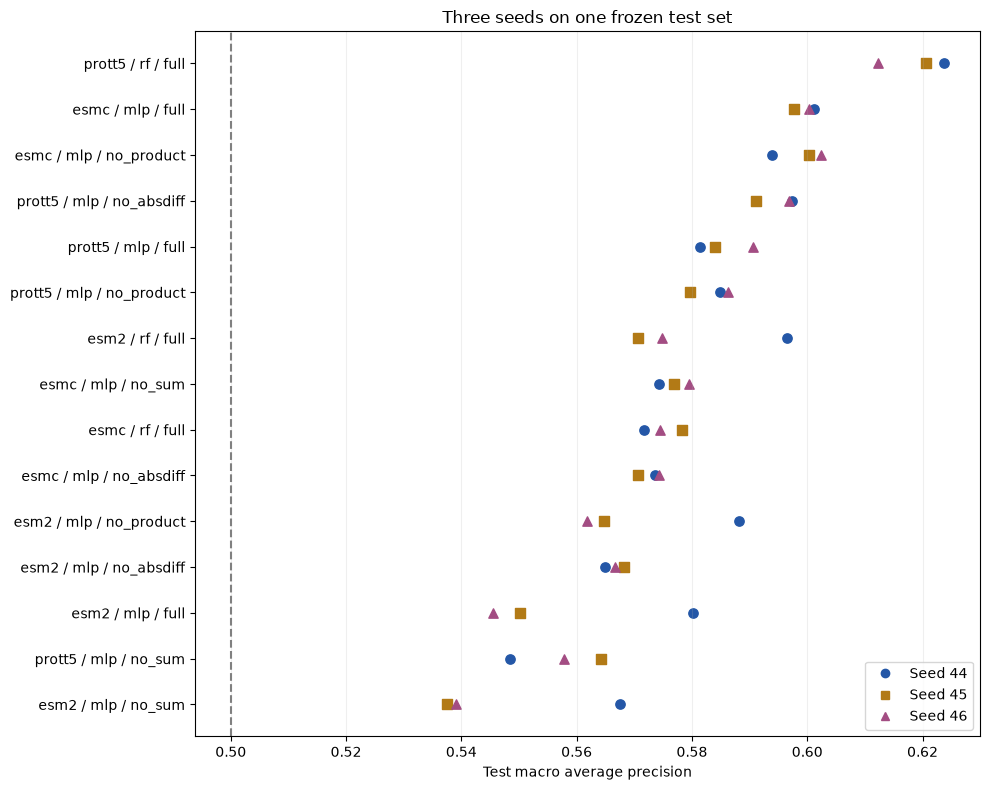

In [2]:
from matplotlib.lines import Line2D
fig,ax=plt.subplots(figsize=(10,8))
for i,label in enumerate(summary.index):
 for seed,marker,color in zip([44,45,46],['o','s','^'],['#2457A7','#B27A16','#A34D83']):
  v=held[(held.model==label)&(held.seed==seed)].macro_ap.iloc[0]
  ax.scatter(v,i,marker=marker,color=color,s=45)
ax.set_yticks(range(len(summary)),summary.index);ax.invert_yaxis()
ax.axvline(.5,color='gray',linestyle='--');ax.set_xlabel('Test macro average precision')
ax.set_title('Three seeds on one frozen test set');ax.grid(axis='x',alpha=.2)
ax.legend(handles=[Line2D([],[],linestyle='',marker=m,color=c,label=f'Seed {s}') for s,m,c in zip([44,45,46],['o','s','^'],['#2457A7','#B27A16','#A34D83'])],loc='lower right')
fig.tight_layout();plt.show()

## Full-feature heads
Class prevalence is approximately 87% positive. Include both class AP values, macro-F1, MCC and Brier score when interpreting performance. Scores have not been established as calibrated biological probabilities.

In [3]:
display(held[held.variant=='full'].groupby(['encoder','head'])[['auroc','positive_ap','negative_ap','macro_ap','macro_f1','mcc','brier']].mean().round(4))

auroc  positive_ap  negative_ap  macro_ap  macro_f1     mcc  \
encoder head                                                                 
esm2    mlp   0.6125       0.9063       0.2110    0.5586    0.5599  0.1282   
        rf    0.6602       0.9309       0.2303    0.5806    0.5329  0.0915   
esmc    mlp   0.6948       0.9354       0.2640    0.5997    0.5745  0.1505   
        rf    0.6672       0.9317       0.2179    0.5748    0.5446  0.1021   
prott5  mlp   0.6652       0.9233       0.2473    0.5853    0.5817  0.1777   
        rf    0.7264       0.9456       0.2922    0.6189    0.5864  0.2087   

               brier  
encoder head          
esm2    mlp   0.2034  
        rf    0.1121  
esmc    mlp   0.1618  
        rf    0.1122  
prott5  mlp   0.2008  
        rf    0.1092

## Dependence and historical reproduction
The largest test component contains 68% of pairs. The following 1,000-draw paired component-bootstrap ranges are exploratory conditional ranges averaged across the same three seeds, with no multiplicity-adjusted significance claim. Removing the largest component changes the population and is only a sensitivity analysis. Historical seed-44 scores differ; NumPy, pandas and scikit-learn changed while PyTorch matched. No causal attribution to a particular library is made.

In [4]:
display(pd.read_csv(DATA/'exploratory_component_intervals.csv').round(4))
display(pd.read_csv(DATA/'component_sensitivity.csv').groupby('model')[['all_macro_ap','without_largest_macro_ap']].mean().round(4))
display(pd.read_csv(DATA/'historical_comparison.csv').round(5))

,comparison,mean_delta,bootstrap_low,bootstrap_high,valid_draws,invalid_draws
0,prott5_rf_full minus prott5_mlp_full,0.0336,-0.0062,0.1248,1000,0
1,prott5_rf_full minus esmc_mlp_full,0.0192,-0.0519,0.0486,1000,0


,all_macro_ap,without_largest_macro_ap
model,,
esm2_mlp_full,0.5586,0.5338
esm2_mlp_no_absdiff,0.5665,0.5608
esm2_mlp_no_product,0.5716,0.5443
esm2_mlp_no_sum,0.5480,0.4742
esm2_rf_full,0.5806,0.5173
esmc_mlp_full,0.5997,0.5731
esmc_mlp_no_absdiff,0.5728,0.5703
esmc_mlp_no_product,0.5989,0.5745
esmc_mlp_no_sum,0.5769,0.5321


,encoder,head,variant,macro_ap_historical,macro_ap_fresh,macro_ap_delta
0,prott5,rf,full,0.61675,0.62378,0.00703
1,prott5,mlp,full,0.58170,0.58141,-0.00029
2,prott5,mlp,no_sum,0.54844,0.54844,0.00000
3,prott5,mlp,no_absdiff,0.59724,0.59732,0.00009
4,prott5,mlp,no_product,0.58509,0.58482,-0.00028
5,esm2,rf,full,0.59015,0.59652,0.00636
6,esm2,mlp,full,0.58099,0.58023,-0.00076
7,esm2,mlp,no_sum,0.56715,0.56749,0.00034
8,esm2,mlp,no_absdiff,0.56692,0.56483,-0.00209
9,esm2,mlp,no_product,0.57253,0.58821,0.01568


## Data isolation and saved verification
All six original input hashes match. All three reconstructed model partition CSV hashes match the historical run. The regenerated cluster mapping hash differs; historical mapping identity is unresolved. Fresh mapping coverage and zero cross-partition cluster/full-sequence/model-input overlap passed. Heuristic MMseqs2 clustering does not prove absence of all remote homology. The receipts below report checks executed in the private cloud workspace, not new raw-data checks in this public notebook.

In [5]:
display(pd.DataFrame(json.loads((DATA/'fresh_verification.json').read_text())))
display(pd.DataFrame(json.loads((DATA/'source_verification.json').read_text())))
print(json.loads((DATA/'partition_reconstruction.json').read_text()))

,seed,fits,test_predictions_verified,selected_epochs_verified
0,44,15,26745,12
1,45,15,26745,12
2,46,15,26745,12


,name,bytes,sha256,matches_published
0,train,44669229,56a9eaacf0af4322e7e318b54beaf1f113a60b82e6e2e3...,True
1,validation,5557519,d6d1177ec417c8bd6517da7618b17fcfb79273758abe8b...,True
2,test,5574700,ff23db8efbc30fc9f0021227f478bb506a3c6a7028470a...,True
3,prott5,69754503,93a72e4aaa6b6f0d9a3cbc4023453bd2747c62e4fe08fc...,True
4,esm2,82308919,ad72211f8c54b897592456a6e339a30233ae5f2cb8b121...,True
5,esmc,78936475,1267e1d40dc8c2d7444e9486b7c34c64ea2485505d6bde...,True


{'train.csv': True, 'validation.csv': True, 'test.csv': True, 'mmseqs2_clusters.csv': False}


## What remains open
97 regression/integration tests and all eight synthetic draft workflows passed; synthetic successes do not establish biological performance. The earlier combined pytest command failed collection; its individual replacement suites passed. Seed 45 was recovered through verified resume after a kernel interruption; its outer recovery duration is not original training time.

This benchmark retains 46.1% of cleaned pairs, uses a previously exposed historical test pool, and has only three training seeds. Feature-removal ablations also change head parameter counts. Legacy ProtT5 cache metadata cannot establish historical preprocessing/revision provenance. Independent confirmation, real unknown-pair mining evidence, and mutation/interface annotations remain open. Full-page HTML visual inspection was blocked; the exported seed plot was inspected directly.